In [1]:
#| echo: false
#| warning: false
#| output: asis

from IPython.display import Markdown, display

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from statsmodels.formula.api import ols
from statsmodels.iolib.summary2 import summary_col

# Не показывать Warning
import warnings
warnings.simplefilter(action='ignore', category=Warning)

# Настройки оформления графиков
plt.rcParams['figure.figsize'] = (8.5, 6)
plt.rcParams['font.size'] = 10
plt.rcParams['axes.labelsize'] = 12
plt.rcParams['axes.titlesize'] = 14

CONST_NAMES = ('const', 'Intercept')


def fmt(x, decimals=3):
    """Число с заданным числом знаков; оценка, которая округляется до нуля, — с тремя значащими цифрами."""
    if pd.isna(x):
        return ''
    text = f'{x:.{decimals}f}'
    if float(text) == 0:
        return f'{x:.3g}' if x != 0 else f'{0:.{decimals}f}'
    return text


def fmt_p(p, decimals=3):
    """P-значение: меньше 0.001 печатается как «<0.001»."""
    return '<0.001' if p < 0.001 else f'{p:.{decimals}f}'


def errors_text(res, case='nom'):
    """Название типа стандартных ошибок подгонки: 'nom' — «неробастные», 'dat' — «по неробастным …»."""
    cov_type = getattr(res, 'cov_type', 'nonrobust')
    if cov_type == 'nonrobust':
        return {'nom': 'неробастные стандартные ошибки',
                'dat': 'по неробастным стандартным ошибкам'}[case]
    return {'nom': f'робастные стандартные ошибки, {cov_type}',
            'dat': f'по робастным стандартным ошибкам {cov_type}'}[case]


def fit_ols(formula, data, robust=False, **kwargs):
    """МНК-подгонка; robust=True — робастные ошибки HC3. Всегда t- и F-распределения (use_t=True)."""
    cov_type = 'HC3' if robust else 'nonrobust'
    return ols(formula, data=data).fit(cov_type=cov_type, use_t=True, **kwargs)


def show_table(df, index=True, align=None):
    """Таблица pandas в Markdown; числа должны быть заранее превращены в строки через fmt."""
    display(Markdown('\n\n' + df.to_markdown(index=index, colalign=align, disable_numparse=True) + '\n\n'))


def nobs_text(res):
    """Строка «Модель была подогнана по N наблюдениям»."""
    n = int(res.nobs)
    word = 'наблюдению' if n % 10 == 1 and n % 100 != 11 else 'наблюдениям'
    return f'Модель была подогнана по {n} {word}.'


def show_coefs(res, decimals=3, show_nobs=True):
    """Оценки коэффициентов: вертикальная таблица «Переменная | Оценка» и число наблюдений."""
    cov_type = getattr(res, 'cov_type', 'nonrobust')
    column = 'Оценка' if cov_type == 'nonrobust' else f'Оценка ({cov_type})'
    table = pd.DataFrame({'Переменная': res.params.index,
                          column: [fmt(b, decimals) for b in res.params]})
    text = table.to_markdown(index=False, colalign=('left', 'right'), disable_numparse=True)
    if show_nobs:
        text += '\n\n' + nobs_text(res)
    display(Markdown('\n\n' + text + '\n\n'))


def display_answer(text, use_callout=True, theme='note', title='Критическое значение'):
    """Ответ в рамке (callout): theme='note' — число, 'tip' — вывод, 'important' — условие."""
    if use_callout:
        head = f'title="{title}" ' if title else ''
        output_md = f'\n\n::: {{.callout-{theme} {head}icon="true"}}\n{text}\n:::\n\n'
    elif title:
        output_md = f'\n\n**{title}:** {text}\n\n'
    else:
        output_md = f'\n\n{text}\n\n'
    display(Markdown(output_md))


def show_conditions(level, errors=None, hypothesis=None, extra=()):
    """Блок «Условия теста»: уровень значимости (доля или список долей), тип ошибок, гипотеза формулой."""
    levels = level if isinstance(level, (list, tuple)) else [level]
    items = ['уровень значимости: **' + ' и '.join(f'{a * 100:g}%' for a in levels) + '**']
    if errors:
        items.append(f'стандартные ошибки: **{errors}**')
    hypotheses = [hypothesis] if isinstance(hypothesis, str) else list(hypothesis or [])
    if len(hypotheses) == 1:
        items.append(f'гипотеза: {hypotheses[0]}')
    else:
        items += [f'гипотеза {i}: {h}' for i, h in enumerate(hypotheses, start=1)]
    items += list(extra)
    display_answer('\n'.join(f'- {item}' for item in items), theme='important', title='Условия теста')


def signif_stars(p):
    """Коды значимости: *** p<0.01, ** p<0.05, * p<0.1."""
    return '***' if p < 0.01 else '**' if p < 0.05 else '*' if p < 0.1 else ''


SIGNIF_LEGEND = '*Signif. codes:* `***` $p<0.01$, `**` $p<0.05$, `*` $p<0.1$'


def print_regression_summary(res, decimals=3, show_signif=True):
    """Таблица t-теста: Coef., Std.Err., t-value, p-value, Signif. Заголовок называет тип ошибок."""
    title = f'**Результаты $t$-теста для коэффициентов ({errors_text(res)}):**'
    table = pd.DataFrame({
        'Coef.': [fmt(b, decimals) for b in res.params],
        'Std.Err.': [fmt(s, decimals) for s in res.bse],
        't-value': [fmt(t, decimals) for t in res.tvalues],
        'p-value': [fmt_p(p, decimals) for p in res.pvalues],
    }, index=res.params.index)
    legend = ''
    if show_signif:
        table['Signif.'] = ['' if name in CONST_NAMES else signif_stars(p)
                            for name, p in res.pvalues.items()]
        legend = '\n\n' + SIGNIF_LEGEND
    align = ('left',) + ('right',) * 4 + (('left',) if show_signif else ())
    display(Markdown(f'\n\n{title}\n\n' + table.to_markdown(colalign=align, disable_numparse=True) + legend + '\n\n'))


def print_significant_coeffs(res, sign_level=0.05, theme='note', title=None):
    """Рамка со списком коэффициентов, значимых на уровне sign_level (без константы)."""
    names = [name for name, p in res.pvalues.items() if p < sign_level and name not in CONST_NAMES]
    if title is None:
        title = f'Коэффициенты, значимые на уровне {sign_level * 100:g}% ({errors_text(res, "dat")})'
    text = ', '.join(f'`{name}`' for name in names) if names else 'Значимых коэффициентов не выявлено.'
    display_answer(text, theme=theme, title=title)


def show_models(models, names=None, decimals=3, regressor_order=(), errors_note=None, info=None):
    """Сравнение регрессий (summary_col): строка Dep. Variable, коды значимости, пояснение про скобки.

    info — словарь {название строки: функция от подгонки} для дополнительных строк (N, F и т. п.).
    """
    table = summary_col(models, model_names=names, stars=True, float_format=f'%0.{decimals}f',
                        regressor_order=list(regressor_order), info_dict=info or {}).tables[0]
    top = pd.DataFrame({col: [m.model.endog_names] for col, m in zip(table.columns, models)},
                       index=['Dep. Variable'])
    table = pd.concat([top, table])
    if errors_note is None:
        errors_note = errors_text(models[0])
    note = f'{SIGNIF_LEGEND}. В скобках — {errors_note}.'
    display(Markdown('\n\n' + table.to_markdown(disable_numparse=True) + '\n\n' + note + '\n\n'))


def show_ci(res, level=0.95, decimals=3):
    """Доверительные интервалы: «Переменная | Нижняя граница | Верхняя граница», заголовок над таблицей."""
    ci = res.conf_int(alpha=1 - level)
    table = pd.DataFrame({'Переменная': ci.index,
                          'Нижняя граница': [fmt(x, decimals) for x in ci[0]],
                          'Верхняя граница': [fmt(x, decimals) for x in ci[1]]})
    title = f'**{level * 100:g}%-е доверительные интервалы ({errors_text(res)}):**'
    display(Markdown(f'\n\n{title}\n\n'
                     + table.to_markdown(index=False, colalign=('left', 'right', 'right'), disable_numparse=True) + '\n\n'))

# --- Помощники листка 9 ---
from statsmodels.stats.outliers_influence import variance_inflation_factor

plt.rcParams['figure.dpi'] = 200

# Загрузка данных
sleep75 = pd.read_csv('../datasets/sleep75.csv')
wage2 = pd.read_csv('../datasets/wage2.csv')

ERRORS = 'неробастные'
T_HYPOTHESIS = r't-тест, значимость каждого коэффициента: $H_0:\beta_j=0$'


def pct(level):
    """Уровень значимости в процентах: 0.05 -> «5%»."""
    return f'{level * 100:g}%'


def regressors(mod):
    """Матрица регрессоров модели (без константы)."""
    return pd.DataFrame(mod.model.exog, columns=mod.model.exog_names).drop(columns='Intercept')


def vif(mod):
    """Показатели VIF регрессоров (без константы)."""
    exog, names = mod.model.exog, mod.model.exog_names
    return pd.Series({name: variance_inflation_factor(exog, i)
                      for i, name in enumerate(names) if name != 'Intercept'})


def show_vif(mod):
    """Вертикальная таблица «Переменная | VIF», два знака."""
    v = vif(mod)
    show_table(pd.DataFrame({'Переменная': v.index, 'VIF': [f'{x:.2f}' for x in v]}),
               index=False, align=('left', 'right'))


def show_corr(mod):
    """Корреляционная матрица регрессоров, три знака."""
    corr = regressors(mod).corr().round(3) + 0.0  # + 0.0 убирает «-0.000»
    display(Markdown('\n\n' + corr.to_markdown(floatfmt='.3f') + '\n\n'))


def plot_corr(mod):
    """Тепловая карта корреляционной матрицы регрессоров."""
    corr = regressors(mod).corr()
    fig, ax = plt.subplots(figsize=(6, 5))
    sns.heatmap(corr, annot=True, fmt='.3f', annot_kws={'size': 8}, cmap='bwr', vmin=-1, vmax=1,
                square=True, linewidths=0.5, cbar_kws={'label': 'Коэффициент корреляции'}, ax=ax)
    plt.setp(ax.get_xticklabels(), rotation=45, ha='right')
    plt.setp(ax.get_yticklabels(), rotation=0)
    plt.show()


def f_test(mod, terms):
    """F-тест совместной значимости коэффициентов при регрессорах terms."""
    names = mod.model.exog_names
    return mod.f_test(np.eye(len(names))[[names.index(term) for term in terms]])


def show_f_test(mod, test):
    """Результат F-теста: статистика, степени свободы, P-значение."""
    table = pd.DataFrame({'F': [f'{test.fvalue:.3f}'], 'df1': [f'{test.df_num:g}'],
                          'df2': [f'{test.df_denom:g}'], 'p-value': [fmt_p(test.pvalue)]})
    display(Markdown(f'\n\n**Результаты $F$-теста ({errors_text(mod)}):**'))
    show_table(table, index=False, align=('right',) * 4)


def f_crit(test, level):
    """Критическое значение F-распределения."""
    return stats.f.ppf(1 - level, dfn=test.df_num, dfd=test.df_denom)


def decision(test, level):
    """Сравнение F-статистики с критическим значением и решение."""
    f_cr = f_crit(test, level)
    if test.fvalue > f_cr:
        return f'$F = {test.fvalue:.3f} > {f_cr:.2f}$, гипотеза $H_0$ отвергается'
    return f'$F = {test.fvalue:.3f} < {f_cr:.2f}$, гипотеза $H_0$ не отвергается'


def signif_list(mod, level):
    """Имена коэффициентов, значимых на уровне level (без константы)."""
    names = [name for name, p in mod.pvalues.items() if p < level and name not in CONST_NAMES]
    return ', '.join(f'`{name}`' for name in names)

::: {.callout-important title="Важно"}
- Логарифм натуральный; константа включается в модель по умолчанию.
- Данные — в папке `datasets/`, описание переменных — в `datasets/data-description.md`.
- VIF и критические значения округляются до 2-х десятичных знаков, остальные ответы — до 3-х. Ответы считаются по неокруглённым оценкам.
- Коэффициенты подписаны как в statsmodels: `Intercept` — константа, `np.log(x)` — $\log x$, `I(x ** 2)` — $x^2$, `I(x * d)` — произведение $x\cdot d$.
- Все тесты в этом листке — с **неробастными** стандартными ошибками; критические значения и P-значения — по t- и F-распределениям.
:::

# Мультиколлинеарность: VIF, t-тест и F-тест

## sleep equation #1

Для набора данных `sleep75` рассмотрим регрессию

`sleep ~ I(totwrk/100) + I(totwrk**2/10000) + age + smsa + male`

Переменные `sleep` (сон) и `totwrk` (занятость) измерены в минутах в неделю, `age` — в годах; `smsa`, `male`, `union`, `south` — бинарные переменные.

In [2]:
#| output: asis
sign_level = 0.05
mod = fit_ols('sleep ~ I(totwrk/100) + I(totwrk**2/10000) + age + smsa + male', sleep75)
display(Markdown(nobs_text(mod)))

Модель была подогнана по 706 наблюдениям.

Вычислите показатели VIF для регрессоров. **Ответ округлите до 2-х десятичных знаков.**

In [3]:
#| output: asis
show_vif(mod)



| Переменная             |   VIF |
|:-----------------------|------:|
| I(totwrk / 100)        |  8.37 |
| I(totwrk ** 2 / 10000) |  8.20 |
| age                    |  1.01 |
| smsa                   |  1.00 |
| male                   |  1.17 |



Вычислите корреляционную матрицу регрессоров. **Ответ округлите до 3-х десятичных знаков.**

In [4]:
#| output: asis
show_corr(mod)



|                        |   I(totwrk / 100) |   I(totwrk ** 2 / 10000) |    age |   smsa |   male |
|:-----------------------|------------------:|-------------------------:|-------:|-------:|-------:|
| I(totwrk / 100)        |             1.000 |                    0.937 | -0.050 | -0.038 |  0.376 |
| I(totwrk ** 2 / 10000) |             0.937 |                    1.000 | -0.046 | -0.051 |  0.351 |
| age                    |            -0.050 |                   -0.046 |  1.000 |  0.025 |  0.032 |
| smsa                   |            -0.038 |                   -0.051 |  0.025 |  1.000 |  0.007 |
| male                   |             0.376 |                    0.351 |  0.032 |  0.007 |  1.000 |



Постройте тепловую карту корреляционной матрицы (@fig-corr-sleep1).

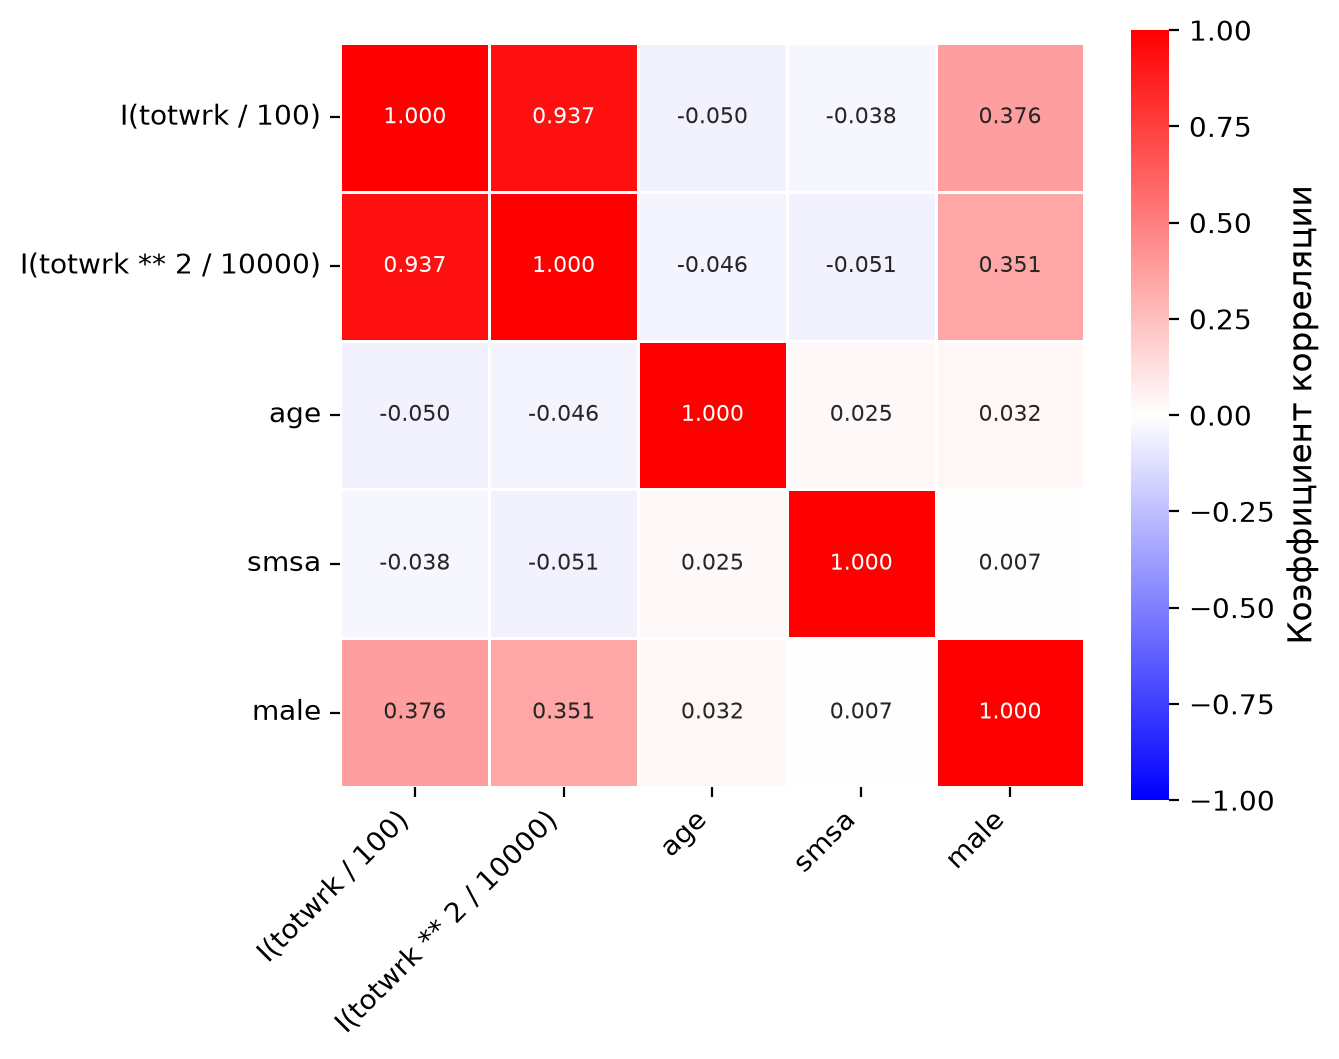

In [5]:
#| label: fig-corr-sleep1
#| fig-cap: "Корреляционная матрица регрессоров (sleep equation #1)"
#| fig-align: "center"
plot_corr(mod)

In [6]:
#| output: asis
show_conditions(sign_level, ERRORS, [
    T_HYPOTHESIS,
    r'F-тест, значимость влияния занятости: $H_0:\beta_{totwrk/100}=\beta_{totwrk^2/10000}=0$'])



::: {.callout-important title="Условия теста" icon="true"}
- уровень значимости: **5%**
- стандартные ошибки: **неробастные**
- гипотеза 1: t-тест, значимость каждого коэффициента: $H_0:\beta_j=0$
- гипотеза 2: F-тест, значимость влияния занятости: $H_0:\beta_{totwrk/100}=\beta_{totwrk^2/10000}=0$
:::



Какие коэффициенты значимы?

In [7]:
#| output: asis
print_regression_summary(mod)
print_significant_coeffs(mod, sign_level)



**Результаты $t$-теста для коэффициентов (неробастные стандартные ошибки):**

|                        |    Coef. |   Std.Err. |   t-value |   p-value | Signif.   |
|:-----------------------|---------:|-----------:|----------:|----------:|:----------|
| Intercept              | 3428.805 |     76.655 |    44.730 |    <0.001 |           |
| I(totwrk / 100)        |   -8.195 |      4.789 |    -1.711 |     0.088 | *         |
| I(totwrk ** 2 / 10000) |   -0.214 |      0.111 |    -1.930 |     0.054 | *         |
| age                    |    2.817 |      1.387 |     2.031 |     0.043 | **        |
| smsa                   |  -78.049 |     32.072 |    -2.434 |     0.015 | **        |
| male                   |   86.639 |     34.200 |     2.533 |     0.012 | **        |

*Signif. codes:* `***` $p<0.01$, `**` $p<0.05$, `*` $p<0.1$





::: {.callout-note title="Коэффициенты, значимые на уровне 5% (по неробастным стандартным ошибкам)" icon="true"}
`age`, `smsa`, `male`
:::



Проверим гипотезу о значимости влияния занятости.

In [8]:
#| output: asis
a, b = 'I(totwrk / 100)', 'I(totwrk ** 2 / 10000)'
test = f_test(mod, [a, b])
show_f_test(mod, test)



**Результаты $F$-теста (неробастные стандартные ошибки):**



|      F |   df1 |   df2 |   p-value |
|-------:|------:|------:|----------:|
| 45.619 |     2 |   700 |    <0.001 |



Вычислите критическое значение. **Ответ округлите до 2-х десятичных знаков.**

In [9]:
#| output: asis
display_answer(f'$F_{{crit}} = {f_crit(test, sign_level):.2f}$')



::: {.callout-note title="Критическое значение" icon="true"}
$F_{crit} = 3.01$
:::



Какой можно сделать вывод?

In [10]:
#| output: asis
p, v, c = mod.pvalues, vif(mod), regressors(mod).corr()
# Проверка: вывод о противоречии верен
assert p[a] > sign_level and p[b] > sign_level and test.fvalue > f_crit(test, sign_level)
display_answer(
    f'{decision(test, sign_level)}.\n\n'
    f'**На первый взгляд противоречие:** коэффициенты при `{a}` и `{b}` по отдельности незначимы '
    f'(P-значения {p[a]:.3f} и {p[b]:.3f}), а гипотеза об их совместной незначимости отвергается. '
    f'Оно объясняется мультиколлинеарностью: корреляция двух регрессоров равна {c.loc[a, b]:.3f}, '
    f'VIF — {v[a]:.2f} и {v[b]:.2f}.',
    theme='tip', title='Вывод')



::: {.callout-tip title="Вывод" icon="true"}
$F = 45.619 > 3.01$, гипотеза $H_0$ отвергается.

**На первый взгляд противоречие:** коэффициенты при `I(totwrk / 100)` и `I(totwrk ** 2 / 10000)` по отдельности незначимы (P-значения 0.088 и 0.054), а гипотеза об их совместной незначимости отвергается. Оно объясняется мультиколлинеарностью: корреляция двух регрессоров равна 0.937, VIF — 8.37 и 8.20.
:::



## sleep equation #2

Для набора данных `sleep75` рассмотрим регрессию

`sleep ~ totwrk + age + I(age**2) + smsa + male + union`

In [11]:
#| output: asis
sign_levels = [0.05, 0.10]
mod = fit_ols('sleep ~ totwrk + age + I(age**2) + smsa + male + union', sleep75)
display(Markdown(nobs_text(mod)))

Модель была подогнана по 706 наблюдениям.

Вычислите показатели VIF для регрессоров. **Ответ округлите до 2-х десятичных знаков.**

In [12]:
#| output: asis
show_vif(mod)



| Переменная   |   VIF |
|:-------------|------:|
| totwrk       |  1.20 |
| age          | 65.40 |
| I(age ** 2)  | 65.56 |
| smsa         |  1.00 |
| male         |  1.17 |
| union        |  1.01 |



Вычислите корреляционную матрицу регрессоров. **Ответ округлите до 3-х десятичных знаков.**

In [13]:
#| output: asis
show_corr(mod)



|             |   totwrk |    age |   I(age ** 2) |   smsa |   male |   union |
|:------------|---------:|-------:|--------------:|-------:|-------:|--------:|
| totwrk      |    1.000 | -0.050 |        -0.067 | -0.038 |  0.376 |   0.002 |
| age         |   -0.050 |  1.000 |         0.992 |  0.025 |  0.032 |  -0.037 |
| I(age ** 2) |   -0.067 |  0.992 |         1.000 |  0.024 |  0.026 |  -0.042 |
| smsa        |   -0.038 |  0.025 |         0.024 |  1.000 |  0.007 |  -0.039 |
| male        |    0.376 |  0.032 |         0.026 |  0.007 |  1.000 |   0.040 |
| union       |    0.002 | -0.037 |        -0.042 | -0.039 |  0.040 |   1.000 |



Постройте тепловую карту корреляционной матрицы (@fig-corr-sleep2).

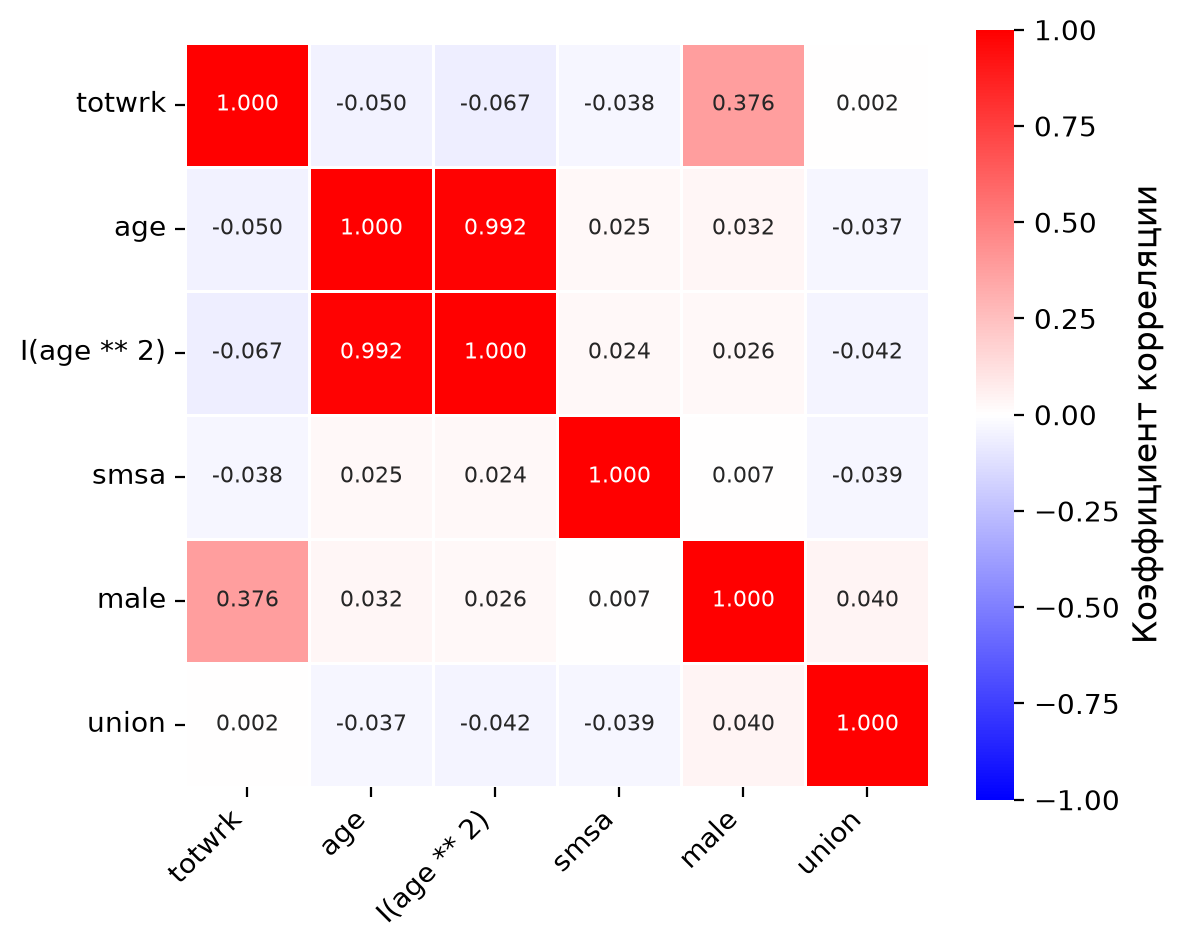

In [14]:
#| label: fig-corr-sleep2
#| fig-cap: "Корреляционная матрица регрессоров (sleep equation #2)"
#| fig-align: "center"
plot_corr(mod)

In [15]:
#| output: asis
show_conditions(sign_levels, ERRORS, [
    T_HYPOTHESIS,
    r'F-тест, значимость влияния возраста: $H_0:\beta_{age}=\beta_{age^2}=0$'])



::: {.callout-important title="Условия теста" icon="true"}
- уровень значимости: **5% и 10%**
- стандартные ошибки: **неробастные**
- гипотеза 1: t-тест, значимость каждого коэффициента: $H_0:\beta_j=0$
- гипотеза 2: F-тест, значимость влияния возраста: $H_0:\beta_{age}=\beta_{age^2}=0$
:::



Какие коэффициенты значимы на каждом из двух уровней?

In [16]:
#| output: asis
print_regression_summary(mod)
display_answer('\n'.join(f'- на уровне {pct(level)}: {signif_list(mod, level)}' for level in sign_levels),
               title=f'Значимые коэффициенты ({errors_text(mod, "dat")})')



**Результаты $t$-теста для коэффициентов (неробастные стандартные ошибки):**

|             |    Coef. |   Std.Err. |   t-value |   p-value | Signif.   |
|:------------|---------:|-----------:|----------:|----------:|:----------|
| Intercept   | 3688.551 |    218.389 |    16.890 |    <0.001 |           |
| totwrk      |   -0.165 |      0.018 |    -9.105 |    <0.001 | ***       |
| age         |   -7.734 |     11.213 |    -0.690 |     0.491 |           |
| I(age ** 2) |    0.127 |      0.134 |     0.948 |     0.343 |           |
| smsa        |  -74.527 |     32.156 |    -2.318 |     0.021 | **        |
| male        |   86.321 |     34.329 |     2.515 |     0.012 | **        |
| union       |    8.574 |     38.195 |     0.224 |     0.822 |           |

*Signif. codes:* `***` $p<0.01$, `**` $p<0.05$, `*` $p<0.1$





::: {.callout-note title="Значимые коэффициенты (по неробастным стандартным ошибкам)" icon="true"}
- на уровне 5%: `totwrk`, `smsa`, `male`
- на уровне 10%: `totwrk`, `smsa`, `male`
:::



Проверим гипотезу о значимости влияния возраста.

In [17]:
#| output: asis
a, b = 'age', 'I(age ** 2)'
test = f_test(mod, [a, b])
show_f_test(mod, test)



**Результаты $F$-теста (неробастные стандартные ошибки):**



|     F |   df1 |   df2 |   p-value |
|------:|------:|------:|----------:|
| 2.497 |     2 |   699 |     0.083 |



Вычислите критические значения для двух уровней значимости. **Ответ округлите до 2-х десятичных знаков.**

In [18]:
#| output: asis
display_answer('\n'.join(f'- уровень значимости {pct(level)}: $F_{{crit}} = {f_crit(test, level):.2f}$'
                         for level in sign_levels), title='Критические значения')



::: {.callout-note title="Критические значения" icon="true"}
- уровень значимости 5%: $F_{crit} = 3.01$
- уровень значимости 10%: $F_{crit} = 2.31$
:::



Какой можно сделать вывод на каждом из двух уровней?

In [19]:
#| output: asis
p, v, c = mod.pvalues, vif(mod), regressors(mod).corr()
# Проверка: на 5% гипотеза не отвергается, на 10% отвергается; age и I(age ** 2) незначимы на обоих уровнях
assert f_crit(test, 0.10) < test.fvalue < f_crit(test, 0.05) and p[a] > 0.10 and p[b] > 0.10
display_answer(
    f'- На уровне 5%: {decision(test, 0.05)}. Противоречия нет: коэффициенты при `{a}` и `{b}` '
    f'незначимы по отдельности (P-значения {p[a]:.3f} и {p[b]:.3f}), и гипотеза об их совместной '
    f'незначимости тоже не отвергается.\n'
    f'- На уровне 10%: {decision(test, 0.10)}, хотя коэффициенты при `{a}` и `{b}` по отдельности '
    f'незначимы. **На первый взгляд противоречие.** Оно объясняется мультиколлинеарностью: '
    f'корреляция `{a}` и `{b}` равна {c.loc[a, b]:.3f}, VIF — {v[a]:.2f} и {v[b]:.2f}.',
    theme='tip', title='Вывод')



::: {.callout-tip title="Вывод" icon="true"}
- На уровне 5%: $F = 2.497 < 3.01$, гипотеза $H_0$ не отвергается. Противоречия нет: коэффициенты при `age` и `I(age ** 2)` незначимы по отдельности (P-значения 0.491 и 0.343), и гипотеза об их совместной незначимости тоже не отвергается.
- На уровне 10%: $F = 2.497 > 2.31$, гипотеза $H_0$ отвергается, хотя коэффициенты при `age` и `I(age ** 2)` по отдельности незначимы. **На первый взгляд противоречие.** Оно объясняется мультиколлинеарностью: корреляция `age` и `I(age ** 2)` равна 0.992, VIF — 65.40 и 65.56.
:::



## sleep equation #3

Для набора данных `sleep75` рассмотрим регрессию

```
sleep ~ totwrk + age + smsa + south +
        I(totwrk*south) + I(age*south) + I(smsa*south)
```

In [20]:
#| output: asis
sign_level = 0.05
mod = fit_ols('sleep ~ totwrk + age + smsa + south + '
              'I(totwrk*south) + I(age*south) + I(smsa*south)', sleep75)
display(Markdown(nobs_text(mod)))

Модель была подогнана по 706 наблюдениям.

Вычислите показатели VIF для регрессоров. **Ответ округлите до 2-х десятичных знаков.**

In [21]:
#| output: asis
show_vif(mod)



| Переменная        |   VIF |
|:------------------|------:|
| totwrk            |  1.15 |
| age               |  1.25 |
| smsa              |  1.19 |
| south             | 22.00 |
| I(totwrk * south) |  8.85 |
| I(age * south)    | 12.28 |
| I(smsa * south)   |  1.29 |



Вычислите корреляционную матрицу регрессоров. **Ответ округлите до 3-х десятичных знаков.**

In [22]:
#| output: asis
show_corr(mod)



|                   |   totwrk |    age |   smsa |   south |   I(totwrk * south) |   I(age * south) |   I(smsa * south) |
|:------------------|---------:|-------:|-------:|--------:|--------------------:|-----------------:|------------------:|
| totwrk            |    1.000 | -0.050 | -0.038 |   0.051 |               0.175 |            0.033 |             0.012 |
| age               |   -0.050 |  1.000 |  0.025 |  -0.018 |              -0.038 |            0.126 |             0.008 |
| smsa              |   -0.038 |  0.025 |  1.000 |  -0.238 |              -0.224 |           -0.222 |             0.209 |
| south             |    0.051 | -0.018 | -0.238 |   1.000 |               0.932 |            0.947 |             0.359 |
| I(totwrk * south) |    0.175 | -0.038 | -0.224 |   0.932 |               1.000 |            0.868 |             0.328 |
| I(age * south)    |    0.033 |  0.126 | -0.222 |   0.947 |               0.868 |            1.000 |             0.351 |
| I(smsa * south)   |    0.012 |  0.008 |  0.209 |   0.359 |               0.328 |            0.351 |             1.000 |



Постройте тепловую карту корреляционной матрицы (@fig-corr-sleep3).

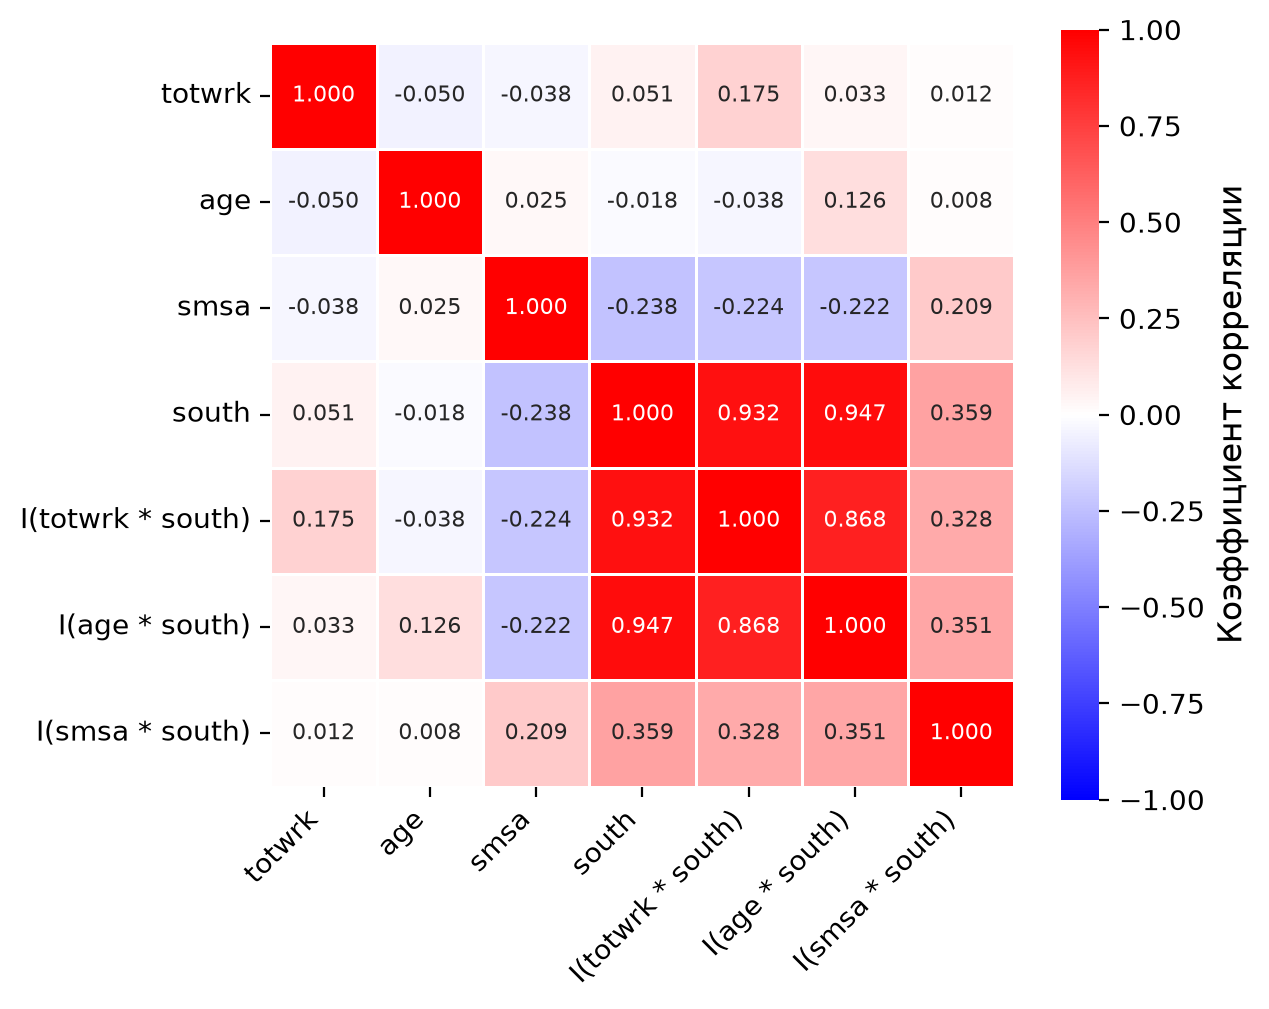

In [23]:
#| label: fig-corr-sleep3
#| fig-cap: "Корреляционная матрица регрессоров (sleep equation #3)"
#| fig-align: "center"
plot_corr(mod)

In [24]:
#| output: asis
show_conditions(sign_level, ERRORS, [
    T_HYPOTHESIS,
    r'F-тест, значимость региона (переменная `south`): '
    r'$H_0:\beta_{south}=\beta_{totwrk\cdot south}=\beta_{age\cdot south}=\beta_{smsa\cdot south}=0$'])



::: {.callout-important title="Условия теста" icon="true"}
- уровень значимости: **5%**
- стандартные ошибки: **неробастные**
- гипотеза 1: t-тест, значимость каждого коэффициента: $H_0:\beta_j=0$
- гипотеза 2: F-тест, значимость региона (переменная `south`): $H_0:\beta_{south}=\beta_{totwrk\cdot south}=\beta_{age\cdot south}=\beta_{smsa\cdot south}=0$
:::



Какие коэффициенты значимы?

In [25]:
#| output: asis
print_regression_summary(mod)
print_significant_coeffs(mod, sign_level)



**Результаты $t$-теста для коэффициентов (неробастные стандартные ошибки):**

|                   |    Coef. |   Std.Err. |   t-value |   p-value | Signif.   |
|:------------------|---------:|-----------:|----------:|----------:|:----------|
| Intercept         | 3557.513 |     75.504 |    47.117 |    <0.001 |           |
| totwrk            |   -0.161 |      0.018 |    -9.062 |    <0.001 | ***       |
| age               |    1.485 |      1.545 |     0.961 |     0.337 |           |
| smsa              |  -61.554 |     34.856 |    -1.766 |     0.078 | *         |
| south             | -407.206 |    189.627 |    -2.147 |     0.032 | **        |
| I(totwrk * south) |    0.078 |      0.050 |     1.556 |     0.120 |           |
| I(age * south)    |    8.267 |      3.495 |     2.365 |     0.018 | **        |
| I(smsa * south)   |   49.429 |    107.111 |     0.461 |     0.645 |           |

*Signif. codes:* `***` $p<0.01$, `**` $p<0.05$, `*` $p<0.1$





::: {.callout-note title="Коэффициенты, значимые на уровне 5% (по неробастным стандартным ошибкам)" icon="true"}
`totwrk`, `south`, `I(age * south)`
:::



Проверим гипотезу о значимости региона.

In [26]:
#| output: asis
terms = ['south', 'I(totwrk * south)', 'I(age * south)', 'I(smsa * south)']
test = f_test(mod, terms)
show_f_test(mod, test)



**Результаты $F$-теста (неробастные стандартные ошибки):**



|     F |   df1 |   df2 |   p-value |
|------:|------:|------:|----------:|
| 3.144 |     4 |   698 |     0.014 |



Вычислите критическое значение. **Ответ округлите до 2-х десятичных знаков.**

In [27]:
#| output: asis
display_answer(f'$F_{{crit}} = {f_crit(test, sign_level):.2f}$')



::: {.callout-note title="Критическое значение" icon="true"}
$F_{crit} = 2.38$
:::



Какой можно сделать вывод?

In [28]:
#| output: asis
p, v = mod.pvalues, vif(mod)
a, b = 'south', 'I(age * south)'
# Проверка: противоречия нет — два коэффициента значимы по отдельности, F-тест отвергает
assert p[a] < sign_level and p[b] < sign_level and test.fvalue > f_crit(test, sign_level)
display_answer(
    f'{decision(test, sign_level)}.\n\n'
    f'Здесь противоречия нет: коэффициенты при `{a}` и `{b}` значимы и по отдельности '
    f'(P-значения {p[a]:.3f} и {p[b]:.3f}), а F-тест отвергает совместную незначимость всех четырёх. '
    f'При этом VIF у `{a}` равен {v[a]:.2f}, у `{b}` — {v[b]:.2f}: высокий VIF увеличивает '
    f'стандартные ошибки, но сам по себе не делает коэффициент незначимым.',
    theme='tip', title='Вывод')



::: {.callout-tip title="Вывод" icon="true"}
$F = 3.144 > 2.38$, гипотеза $H_0$ отвергается.

Здесь противоречия нет: коэффициенты при `south` и `I(age * south)` значимы и по отдельности (P-значения 0.032 и 0.018), а F-тест отвергает совместную незначимость всех четырёх. При этом VIF у `south` равен 22.00, у `I(age * south)` — 12.28: высокий VIF увеличивает стандартные ошибки, но сам по себе не делает коэффициент незначимым.
:::



## wage equation #1

Для набора данных `wage2` рассмотрим регрессию

`np.log(wage) ~ age + I(age**2) + IQ + married + south + urban`

Переменная `wage` — месячный заработок, `age` — возраст в годах, `IQ` — результат теста IQ; `married`, `south`, `urban` — бинарные переменные.

In [29]:
#| output: asis
sign_level = 0.05
mod = fit_ols('np.log(wage) ~ age + I(age**2) + IQ + married + south + urban', wage2)
display(Markdown(nobs_text(mod)))

Модель была подогнана по 935 наблюдениям.

Вычислите показатели VIF для регрессоров. **Ответ округлите до 2-х десятичных знаков.**

In [30]:
#| output: asis
show_vif(mod)



| Переменная   |    VIF |
|:-------------|-------:|
| age          | 632.87 |
| I(age ** 2)  | 632.96 |
| IQ           |   1.05 |
| married      |   1.01 |
| south        |   1.06 |
| urban        |   1.02 |



Вычислите корреляционную матрицу регрессоров. **Ответ округлите до 3-х десятичных знаков.**

In [31]:
#| output: asis
show_corr(mod)



|             |    age |   I(age ** 2) |     IQ |   married |   south |   urban |
|:------------|-------:|--------------:|-------:|----------:|--------:|--------:|
| age         |  1.000 |         0.999 | -0.044 |     0.107 |  -0.029 |  -0.007 |
| I(age ** 2) |  0.999 |         1.000 | -0.043 |     0.107 |  -0.031 |  -0.009 |
| IQ          | -0.044 |        -0.043 |  1.000 |    -0.015 |  -0.210 |   0.039 |
| married     |  0.107 |         0.107 | -0.015 |     1.000 |   0.023 |  -0.040 |
| south       | -0.029 |        -0.031 | -0.210 |     0.023 |   1.000 |  -0.110 |
| urban       | -0.007 |        -0.009 |  0.039 |    -0.040 |  -0.110 |   1.000 |



Постройте тепловую карту корреляционной матрицы (@fig-corr-wage1).

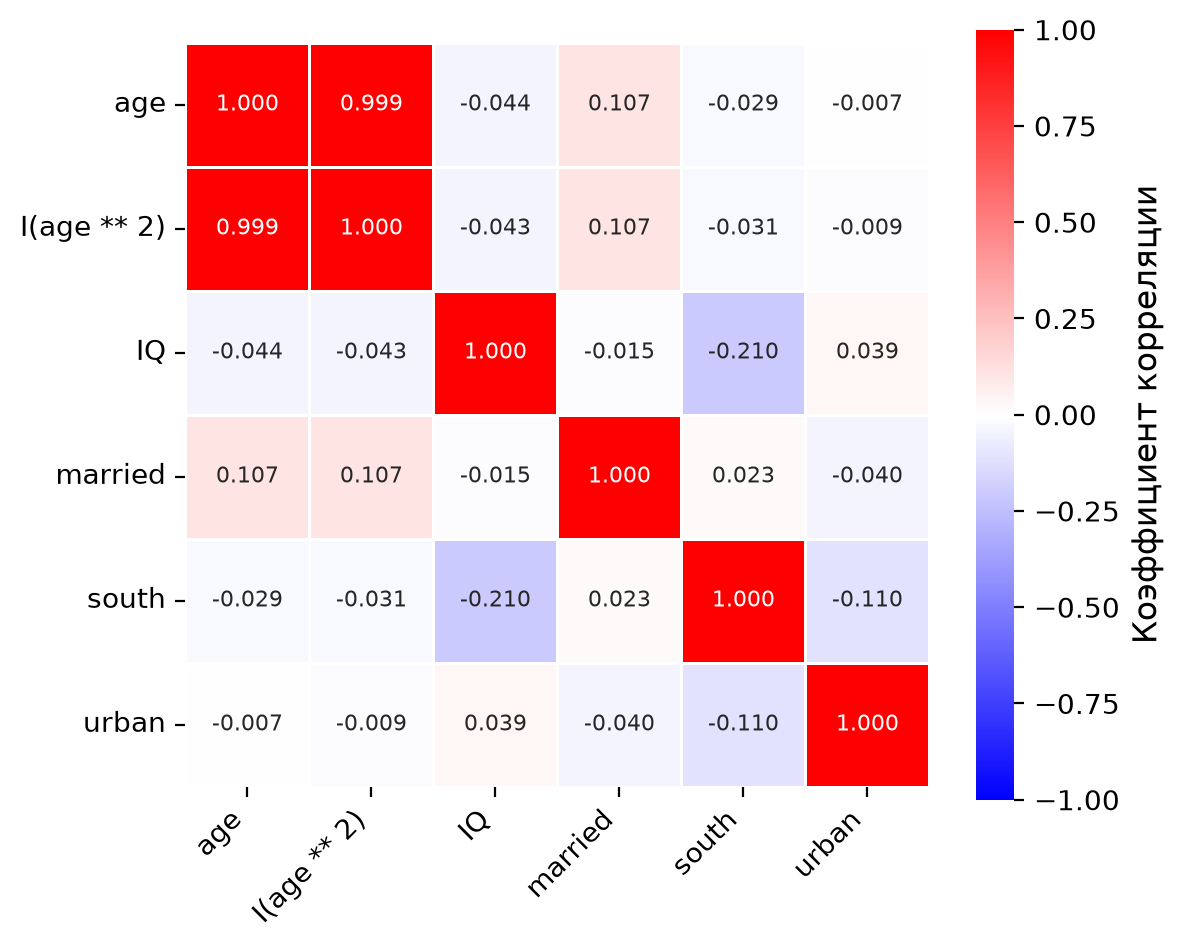

In [32]:
#| label: fig-corr-wage1
#| fig-cap: "Корреляционная матрица регрессоров (wage equation #1)"
#| fig-align: "center"
plot_corr(mod)

In [33]:
#| output: asis
show_conditions(sign_level, ERRORS, [
    T_HYPOTHESIS,
    r'F-тест, значимость влияния возраста: $H_0:\beta_{age}=\beta_{age^2}=0$'])



::: {.callout-important title="Условия теста" icon="true"}
- уровень значимости: **5%**
- стандартные ошибки: **неробастные**
- гипотеза 1: t-тест, значимость каждого коэффициента: $H_0:\beta_j=0$
- гипотеза 2: F-тест, значимость влияния возраста: $H_0:\beta_{age}=\beta_{age^2}=0$
:::



Какие коэффициенты значимы?

In [34]:
#| output: asis
print_regression_summary(mod)
print_significant_coeffs(mod, sign_level)



**Результаты $t$-теста для коэффициентов (неробастные стандартные ошибки):**

|             |   Coef. |   Std.Err. |   t-value |   p-value | Signif.   |
|:------------|--------:|-----------:|----------:|----------:|:----------|
| Intercept   |   2.938 |      1.656 |     1.774 |     0.076 |           |
| age         |   0.145 |      0.100 |     1.447 |     0.148 |           |
| I(age ** 2) |  -0.002 |      0.002 |    -1.236 |     0.217 |           |
| IQ          |   0.008 |      0.001 |     9.770 |    <0.001 | ***       |
| married     |   0.202 |      0.040 |     5.008 |    <0.001 | ***       |
| south       |  -0.100 |      0.027 |    -3.736 |    <0.001 | ***       |
| urban       |   0.173 |      0.028 |     6.260 |    <0.001 | ***       |

*Signif. codes:* `***` $p<0.01$, `**` $p<0.05$, `*` $p<0.1$





::: {.callout-note title="Коэффициенты, значимые на уровне 5% (по неробастным стандартным ошибкам)" icon="true"}
`IQ`, `married`, `south`, `urban`
:::



Проверим гипотезу о значимости влияния возраста.

In [35]:
#| output: asis
a, b = 'age', 'I(age ** 2)'
test = f_test(mod, [a, b])
show_f_test(mod, test)



**Результаты $F$-теста (неробастные стандартные ошибки):**



|      F |   df1 |   df2 |   p-value |
|-------:|------:|------:|----------:|
| 14.833 |     2 |   928 |    <0.001 |



Вычислите критическое значение. **Ответ округлите до 2-х десятичных знаков.**

In [36]:
#| output: asis
display_answer(f'$F_{{crit}} = {f_crit(test, sign_level):.2f}$')



::: {.callout-note title="Критическое значение" icon="true"}
$F_{crit} = 3.01$
:::



Какой можно сделать вывод?

In [37]:
#| output: asis
p, v, c = mod.pvalues, vif(mod), regressors(mod).corr()
# Проверка: вывод о противоречии верен
assert p[a] > sign_level and p[b] > sign_level and test.fvalue > f_crit(test, sign_level)
display_answer(
    f'{decision(test, sign_level)}.\n\n'
    f'**На первый взгляд противоречие:** коэффициенты при `{a}` и `{b}` по отдельности незначимы '
    f'(P-значения {p[a]:.3f} и {p[b]:.3f}), а гипотеза об их совместной незначимости отвергается. '
    f'Оно объясняется мультиколлинеарностью: корреляция `{a}` и `{b}` равна {c.loc[a, b]:.3f}, '
    f'VIF — {v[a]:.2f} и {v[b]:.2f}.',
    theme='tip', title='Вывод')



::: {.callout-tip title="Вывод" icon="true"}
$F = 14.833 > 3.01$, гипотеза $H_0$ отвергается.

**На первый взгляд противоречие:** коэффициенты при `age` и `I(age ** 2)` по отдельности незначимы (P-значения 0.148 и 0.217), а гипотеза об их совместной незначимости отвергается. Оно объясняется мультиколлинеарностью: корреляция `age` и `I(age ** 2)` равна 0.999, VIF — 632.87 и 632.96.
:::



## wage equation #2

Для набора данных `wage2` рассмотрим регрессию

```
np.log(wage) ~ age + IQ + south + urban +
               I(age*urban) + I(IQ*urban) + I(south*urban)
```

In [38]:
#| output: asis
sign_level = 0.01
mod = fit_ols('np.log(wage) ~ age + IQ + south + urban + '
              'I(age*urban) + I(IQ*urban) + I(south*urban)', wage2)
display(Markdown(nobs_text(mod)))

Модель была подогнана по 935 наблюдениям.

Вычислите показатели VIF для регрессоров. **Ответ округлите до 2-х десятичных знаков.**

In [39]:
#| output: asis
show_vif(mod)



| Переменная       |    VIF |
|:-----------------|-------:|
| age              |   3.39 |
| IQ               |   3.88 |
| south            |   3.83 |
| urban            | 175.88 |
| I(age * urban)   | 114.32 |
| I(IQ * urban)    |  53.14 |
| I(south * urban) |   4.09 |



Вычислите корреляционную матрицу регрессоров. **Ответ округлите до 3-х десятичных знаков.**

In [40]:
#| output: asis
show_corr(mod)



|                  |    age |     IQ |   south |   urban |   I(age * urban) |   I(IQ * urban) |   I(south * urban) |
|:-----------------|-------:|-------:|--------:|--------:|-----------------:|----------------:|-------------------:|
| age              |  1.000 | -0.044 |  -0.029 |  -0.007 |            0.137 |          -0.020 |              0.010 |
| IQ               | -0.044 |  1.000 |  -0.210 |   0.039 |            0.030 |           0.260 |             -0.097 |
| south            | -0.029 | -0.210 |   1.000 |  -0.110 |           -0.106 |          -0.136 |              0.741 |
| urban            | -0.007 |  0.039 |  -0.110 |   1.000 |            0.985 |           0.964 |              0.334 |
| I(age * urban)   |  0.137 |  0.030 |  -0.106 |   0.985 |            1.000 |           0.947 |              0.332 |
| I(IQ * urban)    | -0.020 |  0.260 |  -0.136 |   0.964 |            0.947 |           1.000 |              0.288 |
| I(south * urban) |  0.010 | -0.097 |   0.741 |   0.334 |            0.332 |           0.288 |              1.000 |



Постройте тепловую карту корреляционной матрицы (@fig-corr-wage2).

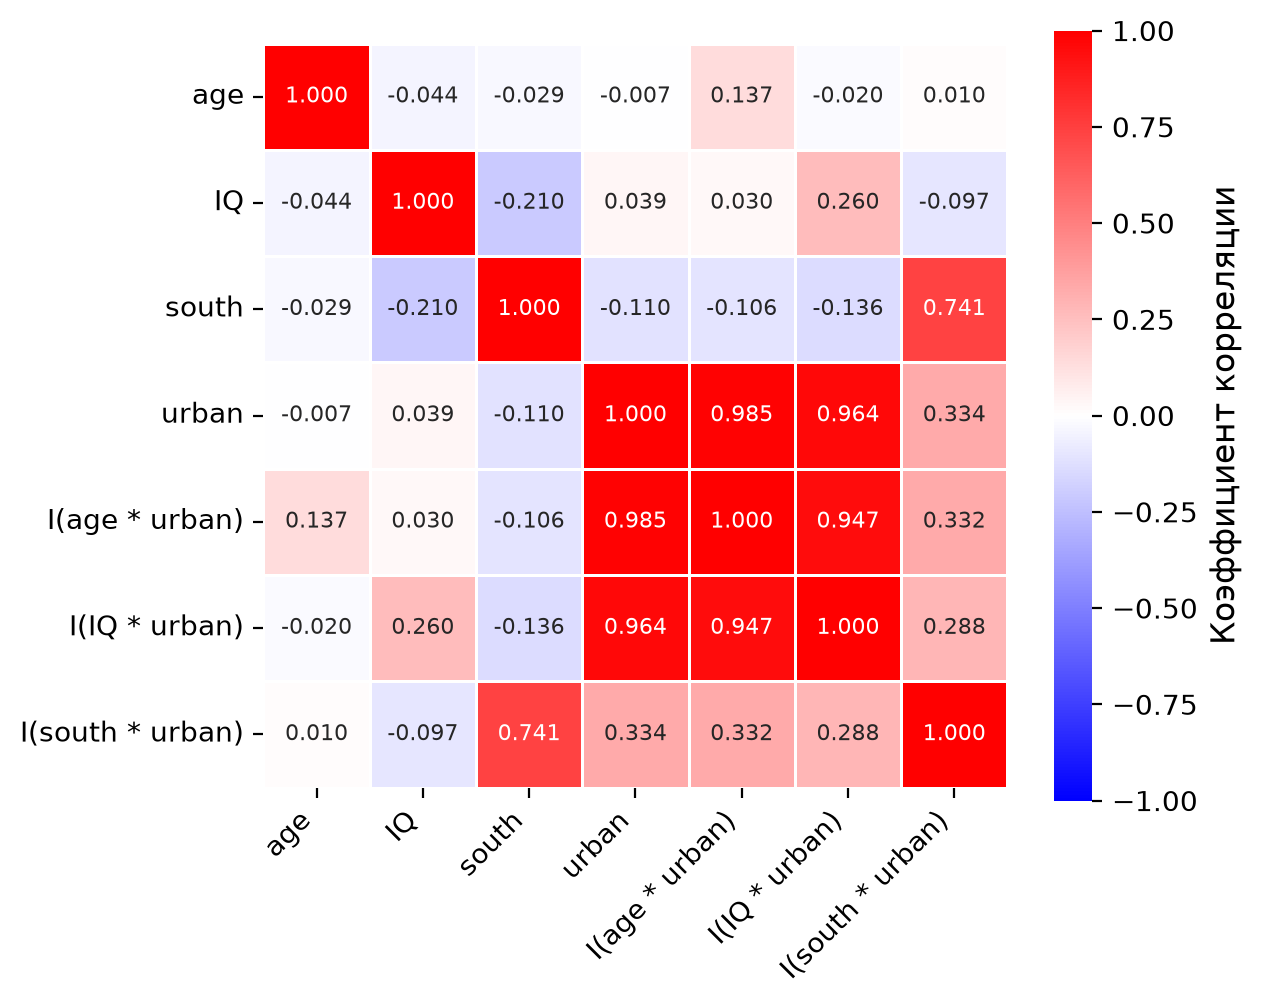

In [41]:
#| label: fig-corr-wage2
#| fig-cap: "Корреляционная матрица регрессоров (wage equation #2)"
#| fig-align: "center"
plot_corr(mod)

In [42]:
#| output: asis
show_conditions(sign_level, ERRORS, [
    T_HYPOTHESIS,
    r'F-тест, значимость влияния места жительства (переменная `urban`): '
    r'$H_0:\beta_{urban}=\beta_{age\cdot urban}=\beta_{IQ\cdot urban}=\beta_{south\cdot urban}=0$'])



::: {.callout-important title="Условия теста" icon="true"}
- уровень значимости: **1%**
- стандартные ошибки: **неробастные**
- гипотеза 1: t-тест, значимость каждого коэффициента: $H_0:\beta_j=0$
- гипотеза 2: F-тест, значимость влияния места жительства (переменная `urban`): $H_0:\beta_{urban}=\beta_{age\cdot urban}=\beta_{IQ\cdot urban}=\beta_{south\cdot urban}=0$
:::



Какие коэффициенты значимы?

In [43]:
#| output: asis
print_regression_summary(mod)
print_significant_coeffs(mod, sign_level)



**Результаты $t$-теста для коэффициентов (неробастные стандартные ошибки):**

|                  |     Coef. |   Std.Err. |   t-value |   p-value | Signif.   |
|:-----------------|----------:|-----------:|----------:|----------:|:----------|
| Intercept        |     4.999 |      0.312 |    16.016 |    <0.001 |           |
| age              |     0.024 |      0.007 |     3.294 |     0.001 | ***       |
| IQ               |     0.008 |      0.002 |     5.116 |    <0.001 | ***       |
| south            |    -0.014 |      0.052 |    -0.271 |     0.787 |           |
| urban            |     0.237 |      0.368 |     0.643 |     0.520 |           |
| I(age * urban)   |    -0.001 |      0.009 |    -0.069 |     0.945 |           |
| I(IQ * urban)    | -1.41e-05 |      0.002 |    -0.007 |     0.994 |           |
| I(south * urban) |    -0.117 |      0.061 |    -1.924 |     0.055 | *         |

*Signif. codes:* `***` $p<0.01$, `**` $p<0.05$, `*` $p<0.1$





::: {.callout-note title="Коэффициенты, значимые на уровне 1% (по неробастным стандартным ошибкам)" icon="true"}
`age`, `IQ`
:::



Проверим гипотезу о значимости влияния места жительства.

In [44]:
#| output: asis
terms = ['urban', 'I(age * urban)', 'I(IQ * urban)', 'I(south * urban)']
test = f_test(mod, terms)
show_f_test(mod, test)



**Результаты $F$-теста (неробастные стандартные ошибки):**



|      F |   df1 |   df2 |   p-value |
|-------:|------:|------:|----------:|
| 10.250 |     4 |   927 |    <0.001 |



Вычислите критическое значение. **Ответ округлите до 2-х десятичных знаков.**

In [45]:
#| output: asis
display_answer(f'$F_{{crit}} = {f_crit(test, sign_level):.2f}$')



::: {.callout-note title="Критическое значение" icon="true"}
$F_{crit} = 3.34$
:::



Какой можно сделать вывод?

In [46]:
#| output: asis
p, v, c = mod.pvalues, vif(mod), regressors(mod).corr()
# Проверка: вывод о противоречии верен
assert (p[terms] > sign_level).all() and test.fvalue > f_crit(test, sign_level)
display_answer(
    f'{decision(test, sign_level)}.\n\n'
    f'**На первый взгляд противоречие:** коэффициент при `urban` и все три коэффициента при '
    f'взаимодействиях с `urban` по отдельности незначимы на уровне {pct(sign_level)} (P-значения от '
    f'{p[terms].min():.3f} до {p[terms].max():.3f}), а гипотеза об их совместной незначимости '
    f'отвергается. Оно объясняется мультиколлинеарностью: корреляции `urban` с `I(age * urban)` и '
    f'`I(IQ * urban)` равны {c.loc["urban", "I(age * urban)"]:.3f} и '
    f'{c.loc["urban", "I(IQ * urban)"]:.3f}, VIF этих трёх регрессоров — '
    f'{v["urban"]:.2f}, {v["I(age * urban)"]:.2f} и {v["I(IQ * urban)"]:.2f}.',
    theme='tip', title='Вывод')



::: {.callout-tip title="Вывод" icon="true"}
$F = 10.250 > 3.34$, гипотеза $H_0$ отвергается.

**На первый взгляд противоречие:** коэффициент при `urban` и все три коэффициента при взаимодействиях с `urban` по отдельности незначимы на уровне 1% (P-значения от 0.055 до 0.994), а гипотеза об их совместной незначимости отвергается. Оно объясняется мультиколлинеарностью: корреляции `urban` с `I(age * urban)` и `I(IQ * urban)` равны 0.985 и 0.964, VIF этих трёх регрессоров — 175.88, 114.32 и 53.14.
:::

